# Variable-basin Oceananigans and Green's-function validation

This weak-flow benchmark exercises variable depth, a beta-plane Coriolis parameter, zonal surface stress, spatially varying surface buoyancy, and a nontrivial interior buoyancy-restoring field. The analytical path first solves the surface-pressure equation on a matching elliptical Gridap mesh, then evaluates the B23 Green's-function velocity at Oceananigans tracer-cell centers.

The Oceananigans basin is an elliptical, grid-fitted immersed domain with a smooth Gaussian depth field. Its solid interface is stair-stepped, while the Green's-function reference uses smooth bathymetry. Bulk metrics exclude one horizontal grid cell next to the immersed boundary. Oceananigans solves full Boussinesq dynamics, so velocity agreement is an asymptotic weak-flow check; buoyancy is the direct equation-(50) comparison.

In [1]:
using Oceananigans
using Gridap
using GridapGmsh
using ForwardDiff
using LinearAlgebra
using Plots
using Statistics

include(normpath(joinpath(pwd(), "..", "TheoryNotes", "VelocityFieldPrototype.jl")))
using .VelocityFieldPrototype
include("SurfacePressureTools.jl")


┌ Warning: You are using Julia v1.13 or later!"
│ Oceananigans is currently tested on Julia v1.12."
│ If you find issues with Julia v1.13 or later,"
│ please report at https://github.com/CliMA/Oceananigans.jl/issues/new
└ @ Oceananigans /Users/twnh/.julia/packages/Oceananigans/q1hfl/src/Oceananigans.jl:136


solve_surface_pressure (generic function with 1 method)

## Variable forcing and geometry

`Hfun` is positive over the wet ellipse, including its vertical sidewall. The Gaussian factor gives nonzero slopes everywhere except at the basin centre. The analytical and numerical *vertical* diffusivities are matched through `nu_ocean = Ek * nu_kernel` and `kappa_ocean = Ek * kappa_kernel`. The Oceananigans closure is vertical-only, matching the Green's-function problem; horizontal diffusion would evolve a different buoyancy equation during the long spin-up.

In [2]:
const Lx, Ly = 2.0, 1.5
const ax, ay = 0.85, 0.60
const Hmin, Hmax = 0.30, 1.00
const f0, beta = 1.0, 0.15
const Ek, Γ = 0.02, 0.20
const nu_kernel, kappa_kernel = 1.0, 1.0
const nu_ocean, kappa_ocean = Ek * nu_kernel, Ek * kappa_kernel
const tau0 = 1e-4
const b_surface_amplitude = 2e-3
const B_vertical_gradient = 1e-2
const B_horizontal_amplitude = 3e-3

inside_ellipse(x, y) = (x / ax)^2 + (y / ay)^2 <= 1.0
function Hfun(x, y)
    inside_ellipse(x, y) || return 0.0
    return Hmin + (Hmax - Hmin) * exp(-2 * ((x / ax)^2 + (y / ay)^2))
end
ffun(x, y) = f0 + beta * y
tau_x(x, y) = tau0 * cos(pi * y / ay)
tau_y(x, y) = 0.0
bsfun(x, y) = b_surface_amplitude * exp(-((x / (0.55ax))^2 + (y / (0.55ay))^2))
Bfun(x, y, z) = B_vertical_gradient * z + B_horizontal_amplitude * sin(pi * x / ax) * (1 + z / Hmax)

parameters = VelocityParameters(Ek, Γ, nu_kernel, kappa_kernel, f0, beta)
kernels = load_symbolic_kernels()
H_x(x, y) = ForwardDiff.derivative(xq -> Hfun(xq, y), x)
H_y(x, y) = ForwardDiff.derivative(yq -> Hfun(x, yq), y)
f_x(x, y) = 0.0
f_y(x, y) = beta

b_green(x, y, z) = buoyancy_from_forcing(parameters, Hfun, Bfun, bsfun, x, y, z)
pressure_mesh = generate_pressure_mesh(
    "Oceananigans_Variable_Basin_Validation_pressure.msh", ellipse_boundary(ax, ay); resolution=0.10,
)
pressure_solution = solve_surface_pressure(
    pressure_mesh, kernels, parameters, Hfun, ffun, f_x, f_y,
    (x, y) -> tau_x(x, y) + im * tau_y(x, y), Bfun, bsfun, H_x, H_y,
)
u_green(x, y, z) = velocity_b23_from_gradps(
    kernels, parameters, Hfun, ffun, f_x, f_y, pressure_solution.gradps,
    (x, y) -> tau_x(x, y) + im * tau_y(x, y), Bfun, bsfun, H_x, H_y, x, y, z,
)

# Oceananigans uses negative top flux for the notebook's positive ∂z u = τ convention.
top_tau_x(x, y, t) = -nu_ocean * tau_x(x, y)
top_tau_y(x, y, t) = -nu_ocean * tau_y(x, y)
surface_buoyancy(x, y, t) = bsfun(x, y)
target_buoyancy(x, y, z, t) = Bfun(x, y, z)
solid(x, y, z) = !inside_ellipse(x, y) || z <= -Hfun(x, y)


Info    : Reading 'Oceananigans_Variable_Basin_Validation_pressure.msh'...
Info    : 193 entities
Info    : 858 nodes
Info    : 1714 elements
Info    : Done reading 'Oceananigans_Variable_Basin_Validation_pressure.msh'


┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 71.7
│   queued_messages = 1
└ @ VSCodeServer.JSONRPC /Users/twnh/.vscode/extensions/julialang.language-julia-1.242.2/scripts/packages/JSONRPC/src/core.jl:414


solid (generic function with 1 method)

In [3]:
function stable_timestep(Nz)
    dz = Hmax / Nz
    return min(0.005, 0.15 * dz^2 / max(nu_ocean, kappa_ocean))
end

function make_variable_basin_simulation(Nz; Nx=24, Ny=20, stop_time=100.0)
    underlying_grid = RectilinearGrid(CPU();
        topology=(Bounded, Bounded, Bounded), size=(Nx, Ny, Nz),
        x=(-Lx / 2, Lx / 2), y=(-Ly / 2, Ly / 2), z=(-Hmax, 0),
    )
    grid = ImmersedBoundaryGrid(
        underlying_grid, GridFittedBoundary(solid); active_cells_map=true,
    )
    u_bcs = FieldBoundaryConditions(top=FluxBoundaryCondition(top_tau_x), immersed=ValueBoundaryCondition(0.0))
    v_bcs = FieldBoundaryConditions(top=FluxBoundaryCondition(top_tau_y), immersed=ValueBoundaryCondition(0.0))
    w_bcs = FieldBoundaryConditions(immersed=ValueBoundaryCondition(0.0))
    b_bcs = FieldBoundaryConditions(top=ValueBoundaryCondition(surface_buoyancy), immersed=FluxBoundaryCondition(0.0))
    model = NonhydrostaticModel(grid;
        advection=nothing, buoyancy=BuoyancyTracer(), coriolis=BetaPlane(f₀=f0, β=beta), tracers=:b,
        closure=VerticalScalarDiffusivity(ν=nu_ocean, κ=kappa_ocean),
        boundary_conditions=(u=u_bcs, v=v_bcs, w=w_bcs, b=b_bcs),
        forcing=(b=Relaxation(rate=Γ, target=target_buoyancy),),
    )
    set!(model, u=0, v=0, w=0, b=(x, y, z) -> inside_ellipse(x, y) && z > -Hfun(x, y) ? b_green(x, y, z) : 0.0)
    return Simulation(model; Δt=stable_timestep(Nz), stop_time)
end

function timed_resources(f)
    GC.gc()
    measurement = @timed f()
    return measurement.value, (seconds=measurement.time, allocated_mib=measurement.bytes / 2.0^20, gc_seconds=measurement.gctime)
end

relative_l2(actual, reference) = norm(actual .- reference) / max(norm(reference), eps(eltype(actual)))

function bulk_wet_mask(model, reference; horizontal_buffer_cells=1, vertical_buffer_cells=1)
    x = collect(xnodes(model.tracers.b))
    y = collect(ynodes(model.tracers.b))
    z = collect(znodes(model.tracers.b))
    dx, dy, dz = abs(x[2] - x[1]), abs(y[2] - y[1]), abs(z[2] - z[1])
    horizontal_margin = horizontal_buffer_cells * max(dx / ax, dy / ay)
    mask = falses(size(reference))
    for k in eachindex(z), j in eachindex(y), i in eachindex(x)
        radius = sqrt((x[i] / ax)^2 + (y[j] / ay)^2)
        mask[i, j, k] = isfinite(reference[i, j, k]) &&
                        radius <= 1 - horizontal_margin &&
                        z[k] >= -Hfun(x[i], y[j]) + vertical_buffer_cells * dz
    end
    return mask
end

function error_summary(actual, reference, mask)
    difference = actual[mask] .- reference[mask]
    reference_values = reference[mask]
    return (
        points = length(difference),
        relative_l2 = relative_l2(actual[mask], reference_values),
        relative_linf = maximum(abs, difference) / max(maximum(abs, reference_values), eps()),
        max_abs = maximum(abs, difference),
        p95_abs = quantile(abs.(difference), 0.95),
        median_abs = median(abs.(difference)),
    )
end


error_summary (generic function with 1 method)

## Common-point diagnostics, performance, and figures

The Green's-function velocity uses the Gridap-computed surface-pressure gradient on the same elliptical footprint. The notebook reports direct buoyancy agreement and separate velocity diagnostics rather than claiming pointwise full-velocity equivalence, because the full Boussinesq and planetary-geostrophic pressure equations differ and Oceananigans represents the immersed interface stair-stepwise.

┌ Warning: The FFT-based pressure_solver for NonhydrostaticModels on ImmersedBoundaryGrid
│ is approximate and will probably produce velocity fields that are divergent
│ adjacent to the immersed boundary. An experimental but improved pressure_solver
│ is available which may be used by writing
│ 
│     using Oceananigans.Solvers: ConjugateGradientPoissonSolver
│     pressure_solver = ConjugateGradientPoissonSolver(grid)
│     model = NonhydrostaticModel(grid; pressure_solver)
│ 
│ Please report issues to https://github.com/CliMA/Oceananigans.jl/issues.
└ @ Oceananigans.Models.NonhydrostaticModels /Users/twnh/.julia/packages/Oceananigans/q1hfl/src/Models/NonhydrostaticModels/NonhydrostaticModels.jl:70
┌ Info: Initializing simulation...
└ @ Oceananigans.Simulations /Users/twnh/.julia/packages/Oceananigans/q1hfl/src/Simulations/run.jl:304
┌ Info:     ... simulation initialization complete (50.647 ms)
└ @ Oceananigans.Simulations /Users/twnh/.julia/packages/Oceananigans/q1hfl/src/Simulation

3-element Vector{@NamedTuple{Nz::Int64, cells::Int64, wet_points::Int64, bulk_points::Int64, wet_relative_l2::Float64, bulk_relative_l2::Float64, bulk_relative_linf::Float64, bulk_p95_abs::Float64, bulk_max_abs::Float64, ocean_seconds::Float64, ocean_allocated_mib::Float64, green_b_seconds::Float64, green_b_allocated_mib::Float64, B23_seconds::Float64, B23_allocated_mib::Float64}}:
 (Nz = 16, cells = 7680, wet_points = 2476, bulk_points = 1896, wet_relative_l2 = 0.03033753480601853, bulk_relative_l2 = 0.024778472704179745, bulk_relative_linf = 0.03629968781834492, bulk_p95_abs = 0.00014738693762809084, bulk_max_abs = 0.0002393519356291736, ocean_seconds = 32.434567583, ocean_allocated_mib = 24828.750595092773, green_b_seconds = 0.062522708, green_b_allocated_mib = 15.490158081054688, B23_seconds = 0.427976458, B23_allocated_mib = 38.7681884765625)
 (Nz = 32, cells = 15360, wet_points = 4928, bulk_points = 3980, wet_relative_l2 = 0.01425327201467345, bulk_relative_l2 = 0.012091042881039

(Lx = 2.0, Ly = 1.5, ax = 0.85, ay = 0.6, Hmin = 0.3, Hmax = 1.0, f0 = 1.0, beta = 0.15, Ek = 0.02, Γ = 0.2, nu_kernel = 1.0, kappa_kernel = 1.0, nu_ocean = 0.02, kappa_ocean = 0.02, tau0 = 0.0001, b_surface_amplitude = 0.002, B_vertical_gradient = 0.01, B_horizontal_amplitude = 0.003, Nx = 24, Ny = 20, test_resolutions = (16, 32, 64), spinup_time = 100.0, B23_horizontal_stride = 2, B23_vertical_stride = 2, timestep_rule = "min(0.005, 0.15 * dz^2 / max(nu_ocean, kappa_ocean))")

(final_bulk_relative_l2 = 0.007435221324424469, target_bulk_relative_l2 = 0.05, final_bulk_relative_linf = 0.01190047095514417, target_bulk_relative_linf = 0.2, refinement_rates = [1.0351485795508506, 0.701491093042667], passed = true)

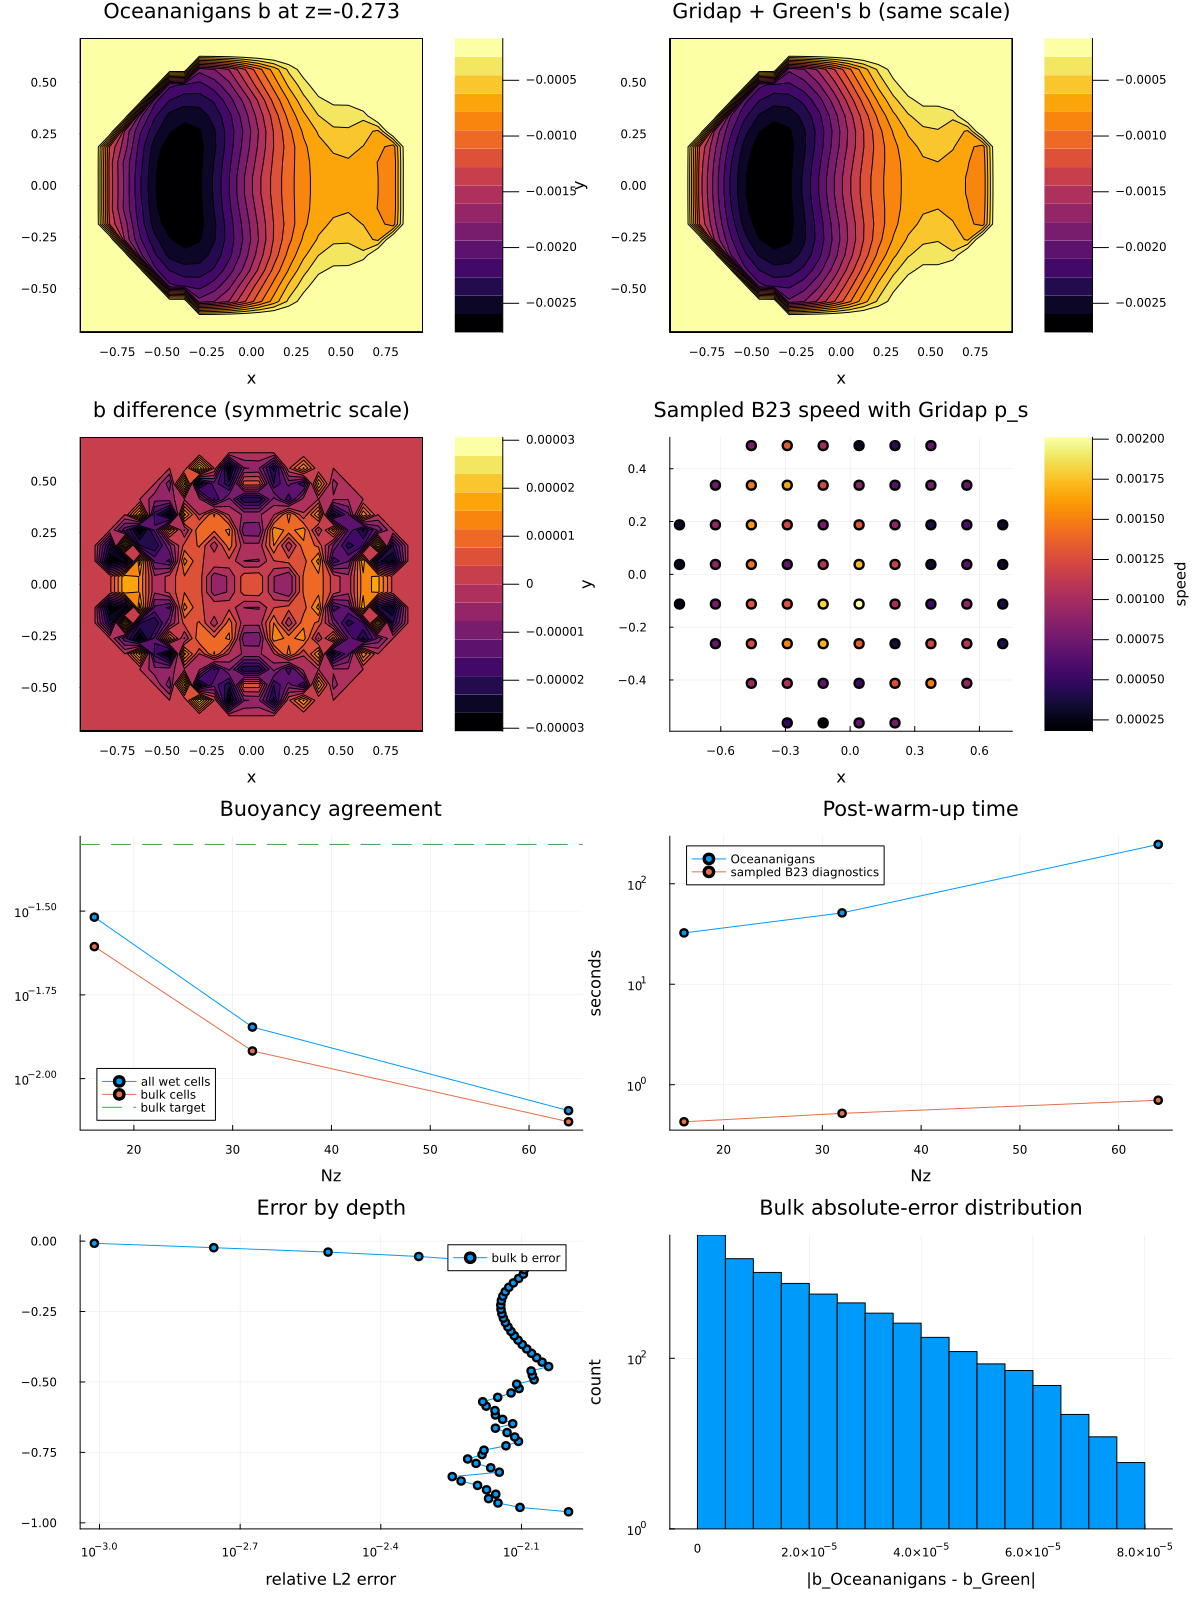

"/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/Oceananigans_Variable_Basin_Validation.png"

In [4]:
const spinup_time = 100.0
const test_resolutions = (16, 32, 64)
const Nx, Ny = 24, 20
const B23_horizontal_stride, B23_vertical_stride = 2, 2

warmup = make_variable_basin_simulation(first(test_resolutions); Nx=8, Ny=8, stop_time=0.05)
run!(warmup)

function green_buoyancy_at_tracer_centers(model)
    b = Array(interior(model.tracers.b))
    x, y, z = collect(xnodes(model.tracers.b)), collect(ynodes(model.tracers.b)), collect(znodes(model.tracers.b))
    reference = fill(NaN, size(b))
    for k in axes(b, 3), j in axes(b, 2), i in axes(b, 1)
        if inside_ellipse(x[i], y[j]) && z[k] > -Hfun(x[i], y[j])
            reference[i, j, k] = b_green(x[i], y[j], z[k])
        end
    end
    return reference
end

function B23_diagnostics_at_tracer_centers(model; horizontal_stride=2, vertical_stride=2)
    x, y, z = collect(xnodes(model.tracers.b)), collect(ynodes(model.tracers.b)), collect(znodes(model.tracers.b))
    u = fill(NaN + im * NaN, length(x), length(y), length(z))
    transport = fill(NaN + im * NaN, length(x), length(y))
    bottom_stress = fill(NaN + im * NaN, length(x), length(y))
    for j in 1:horizontal_stride:length(y), i in 1:horizontal_stride:length(x)
        inside_ellipse(x[i], y[j]) || continue
        transport[i, j] = buoyancy_transport_b23(kernels, parameters, Hfun, ffun, f_x, f_y, Bfun, bsfun, H_x, H_y, x[i], y[j])
        bottom_stress[i, j] = buoyancy_bottom_stress_b23(kernels, parameters, Hfun, ffun, f_x, f_y, Bfun, bsfun, H_x, H_y, x[i], y[j])
        for k in 1:vertical_stride:length(z)
            z[k] > -Hfun(x[i], y[j]) && (u[i, j, k] = u_green(x[i], y[j], z[k]))
        end
    end
    return (; u, transport, bottom_stress)
end

# Compile the B23 velocity, transport, and bottom-stress paths separately.
B23_diagnostics_at_tracer_centers(warmup.model; horizontal_stride=4, vertical_stride=4)

function benchmark_case(Nz)
    simulation, ocean_resources = timed_resources() do
        simulation = make_variable_basin_simulation(Nz; Nx, Ny, stop_time=spinup_time)
        run!(simulation)
        simulation
    end
    green_b, buoyancy_resources = timed_resources(() -> green_buoyancy_at_tracer_centers(simulation.model))
    b_ocean = Array(interior(simulation.model.tracers.b))
    wet_mask = isfinite.(green_b)
    bulk_mask = bulk_wet_mask(simulation.model, green_b)
    b_error = error_summary(b_ocean, green_b, wet_mask)
    b_bulk_error = error_summary(b_ocean, green_b, bulk_mask)
    b23, b23_resources = timed_resources(() -> B23_diagnostics_at_tracer_centers(
        simulation.model; horizontal_stride=B23_horizontal_stride, vertical_stride=B23_vertical_stride,
    ))
    return (; Nz, cells=Nx * Ny * Nz, b_error, b_bulk_error, ocean_resources, buoyancy_resources, b23_resources, simulation, green_b, wet_mask, bulk_mask, b23)
end

results = [benchmark_case(Nz) for Nz in test_resolutions]
diagnostics_table = [(;
    Nz=r.Nz, cells=r.cells, wet_points=r.b_error.points, bulk_points=r.b_bulk_error.points,
    wet_relative_l2=r.b_error.relative_l2, bulk_relative_l2=r.b_bulk_error.relative_l2,
    bulk_relative_linf=r.b_bulk_error.relative_linf, bulk_p95_abs=r.b_bulk_error.p95_abs,
    bulk_max_abs=r.b_bulk_error.max_abs,
    ocean_seconds=r.ocean_resources.seconds, ocean_allocated_mib=r.ocean_resources.allocated_mib,
    green_b_seconds=r.buoyancy_resources.seconds, green_b_allocated_mib=r.buoyancy_resources.allocated_mib,
    B23_seconds=r.b23_resources.seconds, B23_allocated_mib=r.b23_resources.allocated_mib,
) for r in results]
display(diagnostics_table)

case_parameters = (; Lx, Ly, ax, ay, Hmin, Hmax, f0, beta, Ek, Γ, nu_kernel, kappa_kernel,
                   nu_ocean, kappa_ocean, tau0, b_surface_amplitude, B_vertical_gradient,
                   B_horizontal_amplitude, Nx, Ny, test_resolutions, spinup_time,
                   B23_horizontal_stride, B23_vertical_stride,
                   timestep_rule="min(0.005, 0.15 * dz^2 / max(nu_ocean, kappa_ocean))")
display(case_parameters)
@info "Benchmark environment" julia_version=VERSION oceananigans_version=Base.pkgversion(Oceananigans) threads=Threads.nthreads() case_parameters

result = results[end]
model = result.simulation.model
x, y, z = collect(xnodes(model.tracers.b)), collect(ynodes(model.tracers.b)), collect(znodes(model.tracers.b))
b_ocean = Array(interior(model.tracers.b))
k_target = argmin(abs.(z .+ 0.25))
k = 1 + B23_vertical_stride * ((k_target - 1) ÷ B23_vertical_stride)
b_error_slice = b_ocean[:, :, k] .- result.green_b[:, :, k]
b23_speed = abs.(result.b23.u[:, :, k])

plotable(field) = map(value -> isfinite(value) ? value : 0.0, field)
slice_wet_mask = result.wet_mask[:, :, k]
slice_values = vcat(b_ocean[:, :, k][slice_wet_mask], result.green_b[:, :, k][slice_wet_mask])
buoyancy_limits = extrema(slice_values)
error_limit = maximum(abs, b_error_slice[slice_wet_mask])
p1 = contourf(x, y, plotable(b_ocean[:, :, k])'; clims=buoyancy_limits,
              title="Oceananigans b at z=$(round(z[k], digits=3))", xlabel="x", ylabel="y")
p2 = contourf(x, y, plotable(result.green_b[:, :, k])'; clims=buoyancy_limits,
              title="Gridap + Green's b (same scale)", xlabel="x", ylabel="y")
p3 = contourf(x, y, plotable(b_error_slice)'; clims=(-error_limit, error_limit),
              title="b difference (symmetric scale)", xlabel="x", ylabel="y")

finite_speed = findall(isfinite.(b23_speed))
speed_x = [x[index[1]] for index in finite_speed]
speed_y = [y[index[2]] for index in finite_speed]
speed_values = [b23_speed[index] for index in finite_speed]
p4 = scatter(speed_x, speed_y; marker_z=speed_values, markersize=5, label=false,
             xlabel="x", ylabel="y", title="Sampled B23 speed with Gridap p_s", colorbar_title="speed")

Nz_values = [r.Nz for r in results]
wet_l2 = [r.b_error.relative_l2 for r in results]
bulk_l2 = [r.b_bulk_error.relative_l2 for r in results]
bulk_linf = [r.b_bulk_error.relative_linf for r in results]
ocean_seconds = [r.ocean_resources.seconds for r in results]
b23_seconds = [r.b23_resources.seconds for r in results]
refinement_rates = [log(bulk_l2[i - 1] / bulk_l2[i]) / log(Nz_values[i] / Nz_values[i - 1]) for i in 2:length(results)]
acceptance = (
    final_bulk_relative_l2=bulk_l2[end], target_bulk_relative_l2=0.05,
    final_bulk_relative_linf=bulk_linf[end], target_bulk_relative_linf=0.20,
    refinement_rates, passed=bulk_l2[end] <= 0.05 && bulk_linf[end] <= 0.20,
)
display(acceptance)
acceptance.passed ? @info("Bulk buoyancy agreement passes the stated acceptance targets.") :
                    @warn("Bulk buoyancy agreement has not met the stated acceptance targets; increase spin-up, resolution, or interface buffer.")

p5 = plot(Nz_values, wet_l2; marker=:circle, yscale=:log10, label="all wet cells",
          title="Buoyancy agreement", xlabel="Nz", ylabel="relative L2 error")
plot!(p5, Nz_values, bulk_l2; marker=:circle, label="bulk cells")
hline!(p5, [acceptance.target_bulk_relative_l2]; linestyle=:dash, label="bulk target")

p6 = plot(Nz_values, ocean_seconds; marker=:circle, yscale=:log10,
          title="Post-warm-up time", xlabel="Nz", ylabel="seconds", label="Oceananigans")
plot!(p6, Nz_values, b23_seconds; marker=:circle, label="sampled B23 diagnostics")

vertical_l2 = [any(result.bulk_mask[:, :, kk]) ?
    relative_l2(b_ocean[:, :, kk][result.bulk_mask[:, :, kk]], result.green_b[:, :, kk][result.bulk_mask[:, :, kk]]) : NaN
    for kk in eachindex(z)]
p7 = plot(vertical_l2, z; marker=:circle, xscale=:log10, label="bulk b error",
          title="Error by depth", xlabel="relative L2 error", ylabel="z")

bulk_difference = abs.(b_ocean[result.bulk_mask] .- result.green_b[result.bulk_mask])
p8 = histogram(bulk_difference; bins=30, yscale=:log10, label=false,
               title="Bulk absolute-error distribution", xlabel="|b_Oceananigans - b_Green|", ylabel="count")

figure = plot(p1, p2, p3, p4, p5, p6, p7, p8; layout=(4, 2), size=(1200, 1600))
display(figure)
savefig(figure, "Oceananigans_Variable_Basin_Validation.png")
